# Klasifikasi Citra Rock–Paper–Scissors dengan Dense Neural Network dan CNN

**Tujuan:** membandingkan dua model Neural Network standar (fully connected/dense) dengan beberapa model Convolutional Neural Network (CNN) pada tugas klasifikasi tiga kelas: `rock`, `paper`, dan `scissors`.

**Dataset Kaggle:** [Rock-Paper-Scissors Images – drgfreeman](https://www.kaggle.com/datasets/drgfreeman/rockpaperscissors)  
Dataset berisi citra gestur tangan untuk tiga kelas. Dataset asli yang dirujuk proyek ini memiliki 2.188 gambar: 726 `rock`, 710 `paper`, dan 752 `scissors`. Lisensi yang dicantumkan pada halaman Kaggle adalah CC BY-SA 4.0.

> Jalankan notebook ini di Google Colab. Pilih **Runtime → Change runtime type → T4 GPU** jika tersedia. Seluruh skor evaluasi akan dihitung saat notebook dijalankan; jangan mengisi atau mengarang nilai akurasi sebelum eksperimen selesai.

## 1. Persiapan lingkungan

Notebook menggunakan TensorFlow/Keras, scikit-learn, Matplotlib, dan KaggleHub. KaggleHub akan mengunduh dataset langsung dari Kaggle. Jika diminta autentikasi, siapkan token API Kaggle (`kaggle.json`) melalui menu Account pada Kaggle.

In [2]:
!pip -q install kagglehub scikit-learn seaborn

In [3]:
import os
import random
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tensorflow.keras import layers, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU tersedia: []


## 2. Mengunduh dan memeriksa dataset

Struktur folder yang diperlukan adalah satu folder induk yang berisi tiga subfolder kelas: `rock`, `paper`, dan `scissors`. Kode berikut mencari folder tersebut secara otomatis karena susunan folder di dalam arsip Kaggle dapat berbeda.

In [4]:
dataset_path = pathlib.Path(kagglehub.dataset_download("drgfreeman/rockpaperscissors"))
print("Lokasi dataset:", dataset_path)

class_names = ["paper", "rock", "scissors"]
required = set(class_names)

data_dir = None
for candidate in [dataset_path] + list(dataset_path.rglob("*")):
    if candidate.is_dir():
        child_dirs = {p.name.lower() for p in candidate.iterdir() if p.is_dir()}
        if required.issubset(child_dirs):
            data_dir = candidate
            break

if data_dir is None:
    raise FileNotFoundError(
        "Folder kelas paper/rock/scissors tidak ditemukan. "
        "Periksa isi folder hasil unduhan Kaggle."
    )

print("Folder gambar:", data_dir)

Using Colab cache for faster access to the 'rockpaperscissors' dataset.
Lokasi dataset: /kaggle/input/rockpaperscissors
Folder gambar: /kaggle/input/rockpaperscissors


In [5]:
# Mengumpulkan path file gambar dan label berdasarkan nama subfolder.
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
image_paths, labels = [], []

for label_id, class_name in enumerate(class_names):
    class_dir = data_dir / class_name
    files = [p for p in class_dir.rglob("*")
             if p.is_file() and p.suffix.lower() in valid_extensions]
    image_paths.extend([str(p) for p in files])
    labels.extend([label_id] * len(files))

image_paths = np.array(image_paths)
labels = np.array(labels)

counts = pd.Series([class_names[i] for i in labels]).value_counts().reindex(class_names)
display(counts.rename("Jumlah gambar").to_frame())
print("Total gambar:", len(image_paths))

,Jumlah gambar
paper,712
rock,726
scissors,750


Total gambar: 2188


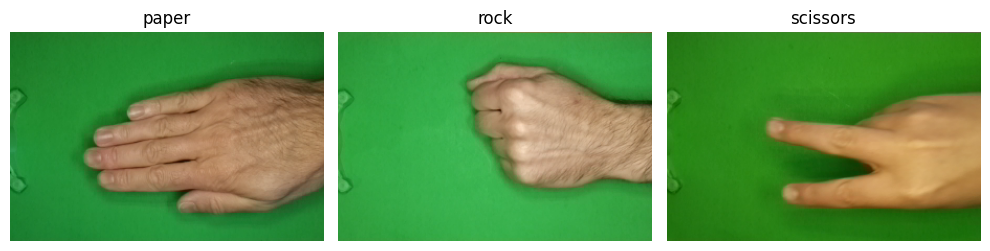

In [6]:
# Visualisasi contoh gambar dari setiap kelas.
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, class_name in zip(axes, class_names):
    idx = np.where(labels == class_names.index(class_name))[0][0]
    img = tf.keras.utils.load_img(image_paths[idx])
    ax.imshow(img)
    ax.set_title(class_name)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Pra-pemrosesan dan pembagian data

Semua gambar diubah menjadi RGB berukuran **64 × 64 piksel** dan dinormalisasi ke rentang 0–1. Data dibagi secara stratified menjadi **70% data latih, 15% validasi, dan 15% pengujian**. Stratified split menjaga proporsi kelas pada setiap subset.

Data validasi digunakan untuk memantau pelatihan dan memilih model. Data uji hanya digunakan pada evaluasi akhir.

In [7]:
IMG_SIZE = (64, 64)
X = np.empty((len(image_paths), IMG_SIZE[0], IMG_SIZE[1], 3), dtype=np.float32)

for i, path in enumerate(image_paths):
    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE, color_mode="rgb")
    X[i] = tf.keras.utils.img_to_array(img) / 255.0

y = labels.astype(np.int32)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)
print("\nDistribusi kelas data uji:")
print(pd.Series([class_names[i] for i in y_test]).value_counts().reindex(class_names))

Train: (1531, 64, 64, 3) Validation: (328, 64, 64, 3) Test: (329, 64, 64, 3)

Distribusi kelas data uji:
paper       107
rock        109
scissors    113
Name: count, dtype: int64


In [8]:
# One-hot encoding untuk categorical crossentropy.
NUM_CLASSES = len(class_names)
y_train_cat = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_val_cat = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)
y_test_cat = tf.keras.utils.to_categorical(y_test, NUM_CLASSES)

## 4. Fungsi pelatihan dan evaluasi

Semua model menggunakan pembagian data dan ukuran citra yang sama agar perbandingan lebih adil. Callback `EarlyStopping` menghentikan pelatihan ketika validation loss tidak membaik, lalu mengembalikan bobot terbaik.

In [9]:
results = []
trained_models = {}
histories = {}

def train_and_evaluate(name, model, epochs=15, batch_size=32):
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
        )
    ]

    history = model.fit(
        X_train, y_train_cat,
        validation_data=(X_val, y_val_cat),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=1
    )

    test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
    y_prob = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    results.append({
        "Model": name,
        "Test Accuracy": float(test_acc),
        "Test Loss": float(test_loss),
        "Parameter": int(model.count_params()),
        "Epoch Terpakai": len(history.history["loss"])
    })
    trained_models[name] = model
    histories[name] = history

    print(f"\n{name} — Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")
    print(classification_report(
        y_test, y_pred, target_names=class_names, zero_division=0
    ))
    return y_pred

## 5. Model Neural Network standar (Dense)

Model dense menerima citra yang telah diubah menjadi vektor satu dimensi (`Flatten`). Model ini tidak secara eksplisit memanfaatkan struktur spasial/pola lokal pada gambar seperti CNN.

- **Dense-1 (sederhana):** satu hidden layer berisi 128 neuron.
- **Dense-2 (lebih kompleks):** dua hidden layer berisi 256 dan 128 neuron, dengan dropout untuk mengurangi overfitting.

Keduanya menggunakan ReLU pada hidden layer dan Softmax pada output tiga kelas.

In [10]:
# Model 1: Dense sederhana
dense_1 = models.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="Dense_Sederhana")

dense_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
pred_dense_1 = train_and_evaluate("Dense-1 (128)", dense_1, epochs=15)

Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.4572 - loss: 1.5768 - val_accuracy: 0.7134 - val_loss: 0.8439 - learning_rate: 0.0010
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.5826 - loss: 0.8499 - val_accuracy: 0.8232 - val_loss: 0.7455 - learning_rate: 0.0010
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6336 - loss: 0.7709 - val_accuracy: 0.8110 - val_loss: 0.6727 - learning_rate: 0.0010
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6786 - loss: 0.6968 - val_accuracy: 0.8140 - val_loss: 0.6537 - learning_rate: 0.0010
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7035 - loss: 0.6502 - val_accuracy: 0.8567 - val_loss: 0.5441 - learning_rate: 0.0010
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.7407 - loss: 0.6194 - val_accuracy: 0.7988 - val_loss: 0.5693 - learning_rate: 0.0010
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.7466 - loss: 0.6062 - val_acc

In [11]:
# Model 2: Dense lebih kompleks
dense_2 = models.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="Dense_Kompleks")

dense_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
pred_dense_2 = train_and_evaluate("Dense-2 (256-128)", dense_2, epochs=15)

Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.3553 - loss: 1.9229 - val_accuracy: 0.3476 - val_loss: 1.0983 - learning_rate: 0.0010
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.4135 - loss: 1.0402 - val_accuracy: 0.4787 - val_loss: 0.9779 - learning_rate: 0.0010
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.4637 - loss: 0.9542 - val_accuracy: 0.6159 - val_loss: 0.8169 - learning_rate: 0.0010
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.5212 - loss: 0.8972 - val_accuracy: 0.6921 - val_loss: 0.7498 - learning_rate: 0.0010
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.5434 - loss: 0.8850 - val_accuracy: 0.7622 - val_loss: 0.6660 - learning_rate: 0.0010
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.5500 - loss: 0.8865 - val_accuracy: 0.5945 - val_loss: 0.8290 - learning_rate: 0.0010
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.4768 - loss: 0.9274 - val_acc

## 6. Model Convolutional Neural Network (CNN)

CNN menggunakan lapisan konvolusi untuk mempelajari pola lokal seperti tepi, bentuk, dan susunan fitur pada citra. Tiga konfigurasi berikut dibandingkan:

1. **CNN-1:** dua blok konvolusi (32 dan 64 filter), baseline.
2. **CNN-2:** tiga blok konvolusi (32, 64, 128 filter), kapasitas lebih besar.
3. **CNN-3:** dua blok konvolusi (32 dan 64 filter), ditambah data augmentation dan dropout lebih besar.

Semua model memakai MaxPooling untuk mengurangi dimensi fitur dan GlobalAveragePooling sebelum klasifikasi.

In [12]:
def build_cnn(filters=(32, 64), dropout=0.30, augmentation=False,
              learning_rate=1e-3, name="CNN"):
    model_layers = [layers.Input(shape=(*IMG_SIZE, 3))]
    if augmentation:
        model_layers.append(layers.RandomFlip("horizontal"))
        model_layers.append(layers.RandomRotation(0.08))
        model_layers.append(layers.RandomZoom(0.10))

    for f in filters:
        model_layers.extend([
            layers.Conv2D(f, 3, padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D()
        ])

    model_layers.extend([
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model = models.Sequential(model_layers, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [13]:
# CNN 1: baseline, dua blok konvolusi.
cnn_1 = build_cnn(filters=(32, 64), dropout=0.30,
                  augmentation=False, name="CNN_Baseline")
pred_cnn_1 = train_and_evaluate("CNN-1 (32-64)", cnn_1, epochs=20)

Epoch 1/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 16s 287ms/step - accuracy: 0.6492 - loss: 0.8284 - val_accuracy: 0.3323 - val_loss: 1.0986 - learning_rate: 0.0010
Epoch 2/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 13s 264ms/step - accuracy: 0.9086 - loss: 0.3897 - val_accuracy: 0.3323 - val_loss: 1.1358 - learning_rate: 0.0010
Epoch 3/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 21s 271ms/step - accuracy: 0.9582 - loss: 0.1770 - val_accuracy: 0.3323 - val_loss: 1.1131 - learning_rate: 0.0010
Epoch 4/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 268ms/step - accuracy: 0.9784 - loss: 0.1015 - val_accuracy: 0.3323 - val_loss: 1.1085 - learning_rate: 5.0000e-04
Epoch 5/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 13s 265ms/step - accuracy: 0.9824 - loss: 0.0812 - val_accuracy: 0.3323 - val_loss: 1.1075 - learning_rate: 5.0000e-04

CNN-1 (32-64) — Test accuracy: 0.3313 | Test loss: 1.0987
              precision    recall  f1-score   support

       paper       0.00      0.00      0.00       107
        rock       0.33      1.00      0.50       109
    s

In [14]:
# CNN 2: lebih dalam dan memiliki lebih banyak filter.
cnn_2 = build_cnn(filters=(32, 64, 128), dropout=0.40,
                  augmentation=False, name="CNN_Dalam")
pred_cnn_2 = train_and_evaluate("CNN-2 (32-64-128)", cnn_2, epochs=20)

Epoch 1/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 404ms/step - accuracy: 0.8354 - loss: 0.4781 - val_accuracy: 0.3323 - val_loss: 1.2037 - learning_rate: 0.0010
Epoch 2/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 19s 380ms/step - accuracy: 0.9667 - loss: 0.1136 - val_accuracy: 0.3323 - val_loss: 2.1660 - learning_rate: 0.0010
Epoch 3/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 21s 441ms/step - accuracy: 0.9811 - loss: 0.0631 - val_accuracy: 0.3323 - val_loss: 3.5642 - learning_rate: 0.0010
Epoch 4/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 19s 407ms/step - accuracy: 0.9928 - loss: 0.0317 - val_accuracy: 0.3323 - val_loss: 5.7156 - learning_rate: 5.0000e-04
Epoch 5/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 458ms/step - accuracy: 0.9935 - loss: 0.0199 - val_accuracy: 0.3323 - val_loss: 7.1723 - learning_rate: 5.0000e-04

CNN-2 (32-64-128) — Test accuracy: 0.3313 | Test loss: 1.2021
              precision    recall  f1-score   support

       paper       0.00      0.00      0.00       107
        rock       0.33      1.00      0.50       109
 

In [15]:
# CNN 3: baseline dengan augmentasi dan dropout lebih tinggi.
cnn_3 = build_cnn(filters=(32, 64), dropout=0.50,
                  augmentation=True, learning_rate=5e-4,
                  name="CNN_Augmentasi")
pred_cnn_3 = train_and_evaluate("CNN-3 (Augmentation)", cnn_3, epochs=20)

Epoch 1/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 361ms/step - accuracy: 0.5212 - loss: 0.9797 - val_accuracy: 0.3323 - val_loss: 1.0982 - learning_rate: 5.0000e-04
Epoch 2/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 346ms/step - accuracy: 0.7446 - loss: 0.7047 - val_accuracy: 0.3323 - val_loss: 1.1135 - learning_rate: 5.0000e-04
Epoch 3/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 16s 331ms/step - accuracy: 0.8681 - loss: 0.5032 - val_accuracy: 0.3323 - val_loss: 1.1431 - learning_rate: 5.0000e-04
Epoch 4/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 308ms/step - accuracy: 0.9014 - loss: 0.3774 - val_accuracy: 0.3323 - val_loss: 1.1457 - learning_rate: 2.5000e-04
Epoch 5/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 304ms/step - accuracy: 0.9282 - loss: 0.3119 - val_accuracy: 0.3323 - val_loss: 1.1485 - learning_rate: 2.5000e-04

CNN-3 (Augmentation) — Test accuracy: 0.3313 | Test loss: 1.0979
              precision    recall  f1-score   support

       paper       0.00      0.00      0.00       107
        rock       0.33      1.00      0

## 7. Perbandingan hasil seluruh model

Tabel berikut disusun otomatis berdasarkan hasil pengujian pada test set. Akurasi yang lebih tinggi menunjukkan proporsi prediksi benar yang lebih besar, sedangkan test loss yang lebih rendah menunjukkan kesalahan probabilistik yang lebih kecil.

,Model,Test Accuracy,Test Loss,Parameter,Epoch Terpakai
0,Dense-1 (128),0.8875,0.3545,"1,573,379",15
1,Dense-2 (256-128),0.7356,0.7211,"3,179,267",9
2,CNN-1 (32-64),0.3313,1.0987,"28,483",5
3,CNN-2 (32-64-128),0.3313,1.2021,"111,043",5
4,CNN-3 (Augmentation),0.3313,1.0979,"28,483",5


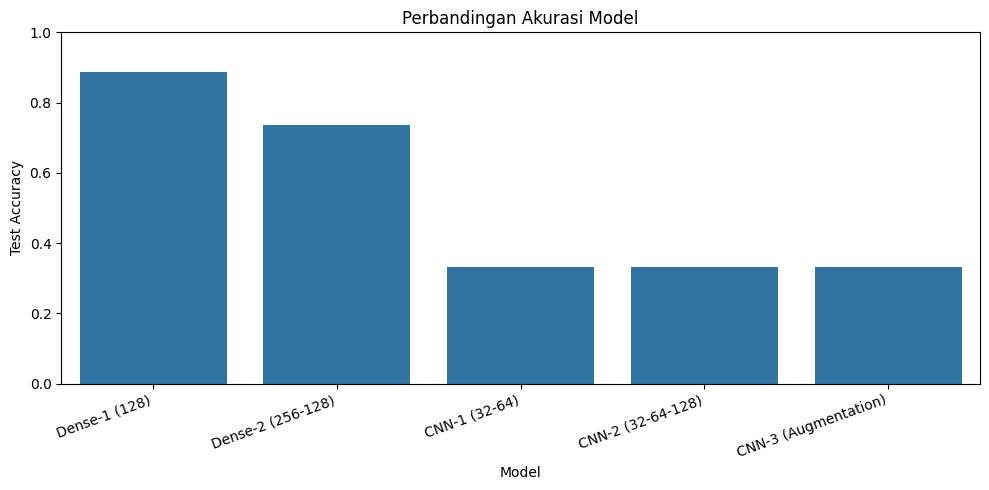

In [16]:
results_df = pd.DataFrame(results).sort_values(
    by="Test Accuracy", ascending=False
).reset_index(drop=True)

display(results_df.style.format({
    "Test Accuracy": "{:.4f}",
    "Test Loss": "{:.4f}",
    "Parameter": "{:,}"
}))

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="Test Accuracy")
plt.ylim(0, 1)
plt.ylabel("Test Accuracy")
plt.title("Perbandingan Akurasi Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

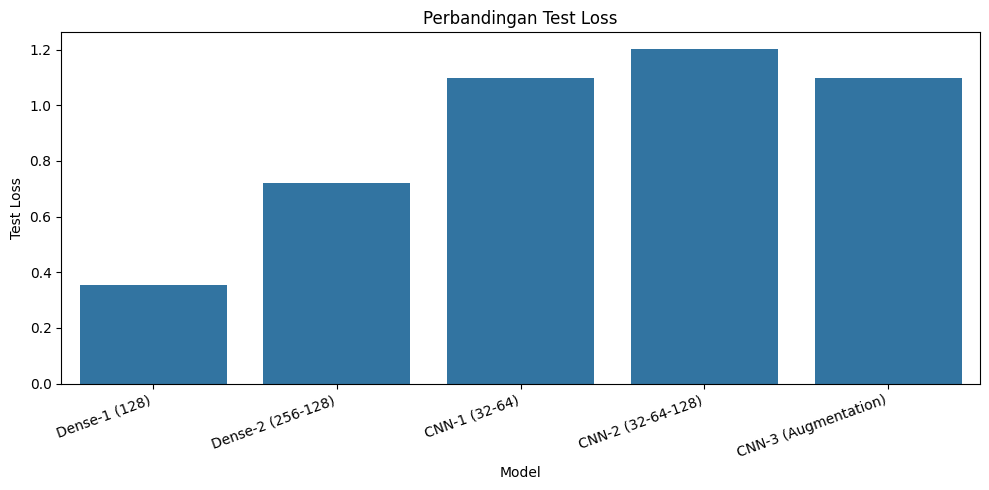

In [17]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="Test Loss")
plt.ylabel("Test Loss")
plt.title("Perbandingan Test Loss")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 8. Kurva pelatihan: accuracy dan loss

Kurva training dan validation membantu mengidentifikasi overfitting maupun underfitting. Jika training accuracy terus naik tetapi validation accuracy tertahan atau turun, model kemungkinan mengalami overfitting. Jika keduanya rendah, model mungkin belum cukup belajar (underfitting).

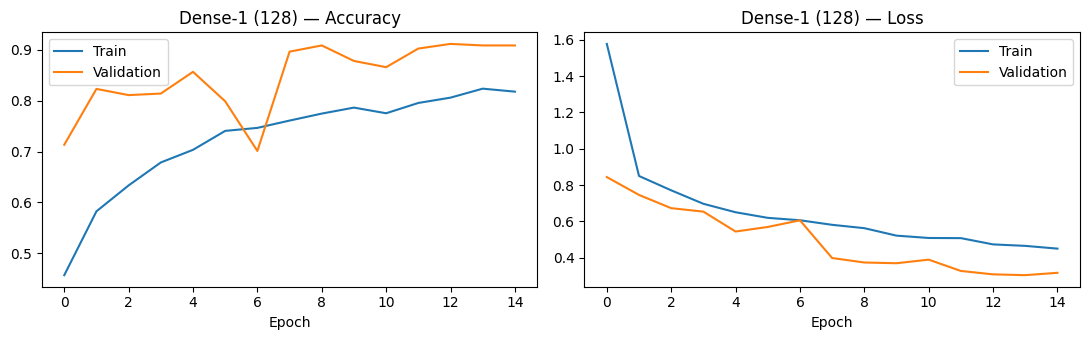

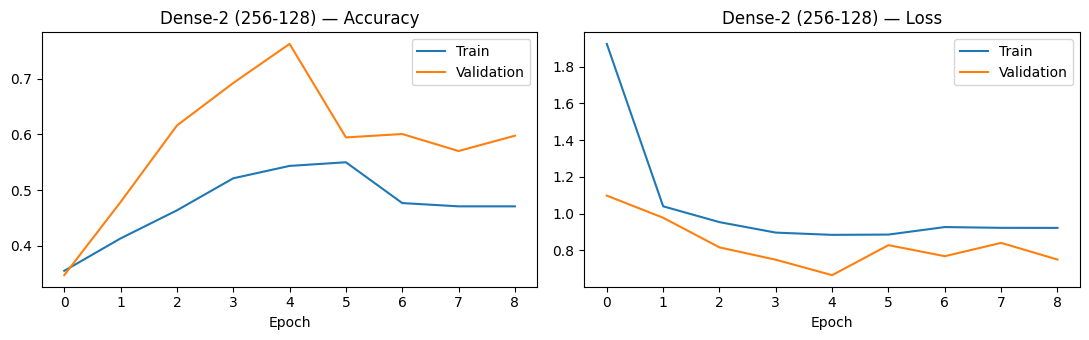

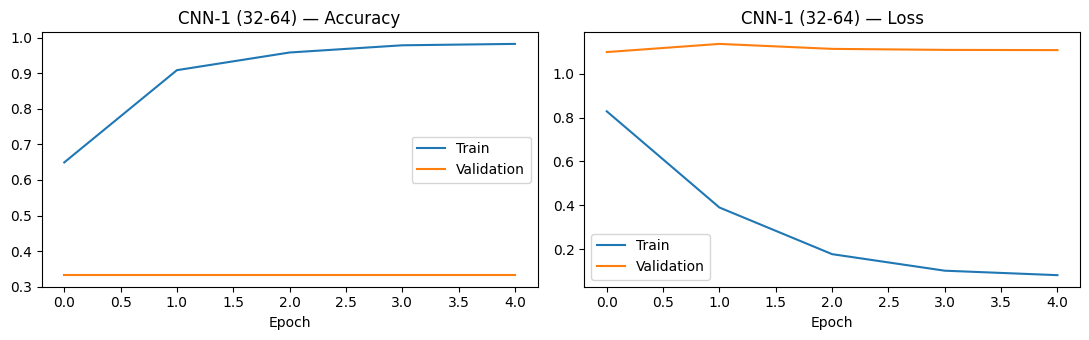

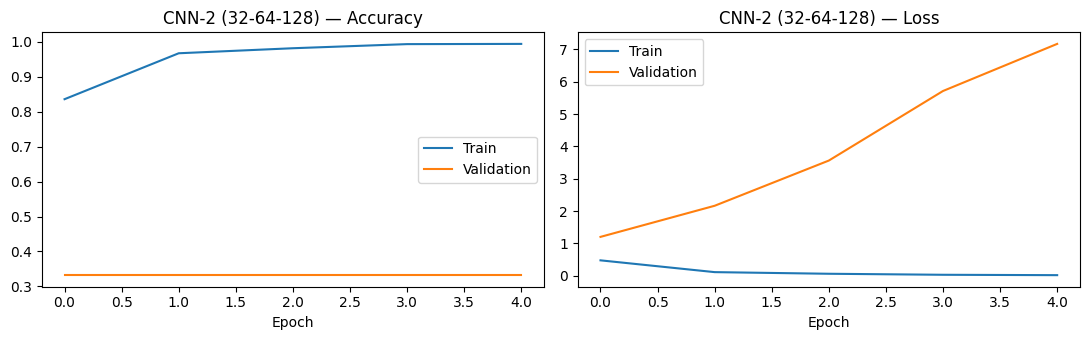

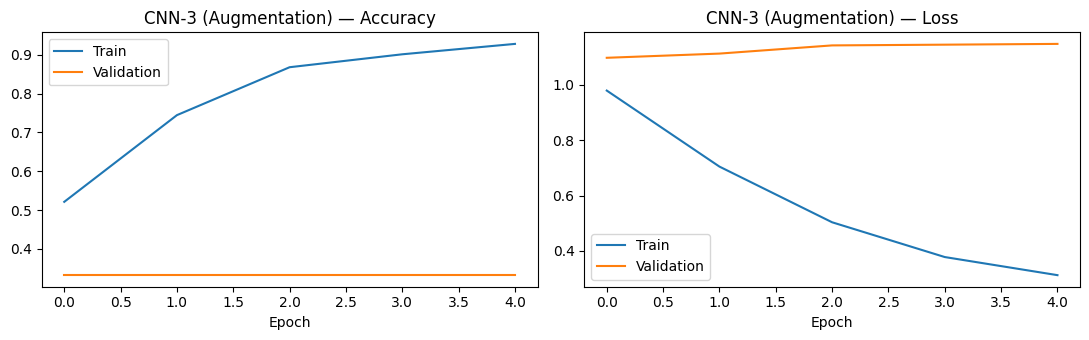

In [18]:
for name, history in histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(history.history["accuracy"], label="Train")
    axes[0].plot(history.history["val_accuracy"], label="Validation")
    axes[0].set_title(f"{name} — Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history.history["loss"], label="Train")
    axes[1].plot(history.history["val_loss"], label="Validation")
    axes[1].set_title(f"{name} — Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## 9. Confusion matrix model terbaik

Confusion matrix memperlihatkan jumlah prediksi benar dan salah untuk setiap kelas. Baris menunjukkan label sebenarnya, sedangkan kolom menunjukkan hasil prediksi.

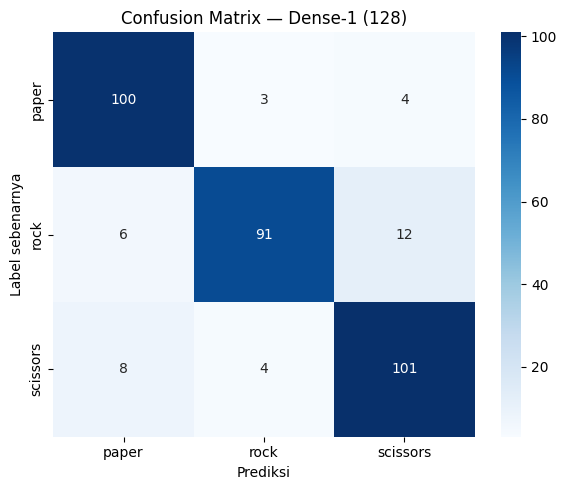

Model terbaik berdasarkan test accuracy: Dense-1 (128)
              precision    recall  f1-score   support

       paper       0.88      0.93      0.90       107
        rock       0.93      0.83      0.88       109
    scissors       0.86      0.89      0.88       113

    accuracy                           0.89       329
   macro avg       0.89      0.89      0.89       329
weighted avg       0.89      0.89      0.89       329



In [19]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
best_prob = best_model.predict(X_test, verbose=0)
best_pred = np.argmax(best_prob, axis=1)

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi")
plt.ylabel("Label sebenarnya")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

print("Model terbaik berdasarkan test accuracy:", best_name)
print(classification_report(
    y_test, best_pred, target_names=class_names, zero_division=0
))

## 10. Analisis hasil dan pembahasan

Gunakan hasil aktual yang muncul setelah seluruh sel dijalankan untuk melengkapi analisis berikut. Jangan menyimpulkan bahwa CNN selalu menang; kesimpulan harus mengikuti tabel dan grafik eksperimen.

1. **Dense dibandingkan CNN.** Model dense mengubah seluruh piksel menjadi vektor sehingga hubungan spasial antar-piksel tidak dipertahankan secara eksplisit. CNN mempelajari fitur spasial melalui filter konvolusi dan biasanya lebih sesuai untuk klasifikasi citra.
2. **Kompleksitas Dense.** Bandingkan Dense-1 dan Dense-2 dari sisi akurasi, loss, jumlah parameter, dan jarak kurva training-validation. Penambahan neuron/layer tidak selalu meningkatkan performa karena dapat meningkatkan risiko overfitting.
3. **Kedalaman CNN.** Bandingkan CNN-1 dan CNN-2. Filter lebih banyak dapat mempelajari fitur lebih kompleks, tetapi juga menambah parameter dan waktu pelatihan.
4. **Pengaruh augmentasi.** Bandingkan CNN-1 dan CNN-3. Augmentasi memperkaya variasi data saat training dan dapat membantu generalisasi, tetapi transformasi yang terlalu kuat juga dapat mengganggu ciri penting gambar.
5. **Kesalahan klasifikasi.** Periksa confusion matrix dan classification report untuk mengetahui kelas yang paling sering tertukar. Precision, recall, dan F1-score perlu dipertimbangkan selain accuracy, terutama jika jumlah data antar kelas tidak seimbang.

### Template kesimpulan

Berdasarkan pengujian terhadap lima konfigurasi model, model dengan performa terbaik adalah **[nama model]** dengan test accuracy sebesar **[nilai]** dan test loss sebesar **[nilai]**. Hasil tersebut menunjukkan bahwa **[uraikan perbandingan Dense dan CNN berdasarkan hasil aktual]**. Perubahan hyperparameter berupa **[jumlah filter/kedalaman/dropout/augmentasi/learning rate]** memberikan **[dampak berdasarkan hasil]** terhadap performa. Dengan mempertimbangkan akurasi, loss, jumlah parameter, dan pola kurva pelatihan, **[nama model]** menjadi konfigurasi yang paling sesuai untuk dataset ini.

### Catatan keterbatasan

Dataset relatif kecil dan latar belakang gambar cenderung konsisten. Karena itu, performa pada dataset ini belum tentu sama ketika model menerima gambar dari kamera dengan latar, pencahayaan, orientasi, atau jarak yang berbeda. Pengujian dengan gambar baru dari kondisi nyata dapat menjadi eksperimen lanjutan.

## 11. Menyimpan model terbaik

Bagian opsional ini menyimpan model dengan test accuracy tertinggi agar dapat digunakan kembali.

In [20]:
best_model.save("model_klasifikasi_rps.keras")
print("Model tersimpan sebagai model_klasifikasi_rps.keras")

Model tersimpan sebagai model_klasifikasi_rps.keras
